In [1]:
import os
import glob
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
from scipy.signal import find_peaks, peak_widths, welch
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="darkgrid", context="notebook")

TARGET_STROKE = "hit_low" 
data_dir = os.path.join("..", "data", "raw", TARGET_STROKE)
wav_files = glob.glob(os.path.join(data_dir, "*.wav"))

if not wav_files:
    print(f"No .wav files found for '{TARGET_STROKE}' in {data_dir}.")

y, sr = librosa.load(wav_files[0], sr=44100)
y, _ = librosa.effects.trim(y, top_db=30)

In [2]:
transient_samples = int(0.02 * sr) # 20 milliseconds
y_transient = y[:transient_samples]

# Compute FFT of the noise burst
D_transient = np.abs(librosa.stft(y_transient, n_fft=1024, hop_length=256))
mean_transient_spectrum = np.mean(D_transient, axis=1)
freqs_transient = librosa.fft_frequencies(sr=sr, n_fft=1024)

# Smooth the spectrum to get the general EQ curve (the Spectral Envelope)
smoothed_noise = np.convolve(mean_transient_spectrum, np.ones(10)/10, mode='same')
noise_db = librosa.amplitude_to_db(smoothed_noise, ref=np.max)

# Find the center frequency of the noise burst
noise_peak_idx = np.argmax(noise_db)
noise_center_freq = freqs_transient[noise_peak_idx]

print("--- Pure Data Parameters: THE EXCITER (Noise Slap) ---")
print(f"-> Center [vcf~] or [bp~] frequency at: {noise_center_freq:.0f} Hz")
print(f"-> Envelope: Very fast attack (1-2ms), fast decay (20-40ms)")

--- Pure Data Parameters: THE EXCITER (Noise Slap) ---
-> Center [vcf~] or [bp~] frequency at: 301 Hz
-> Envelope: Very fast attack (1-2ms), fast decay (20-40ms)


In [5]:
y_decay = y[int(0.05 * sr):] # The ringing tail
freqs, psd = welch(y_decay, fs=sr, nperseg=8192)
psd_db = 10 * np.log10(psd / np.max(psd))

# Find the peaks
peaks, _ = find_peaks(psd_db, prominence=15, distance=10)
sorted_peaks = peaks[np.argsort(psd_db[peaks])[::-1]][:10] # Top 5 loudest modes

# Calculate the Full Width at Half Maximum (FWHM) to get Bandwidth
# rel_height=0.5 means we measure the width halfway down the peak's prominence
widths, width_heights, left_ips, right_ips = peak_widths(psd_db, sorted_peaks, rel_height=0.5)

print("\n--- Pure Data Parameters: THE RESONATOR (Filter Bank) ---")
pd_patch_data = []

for i, peak_idx in enumerate(sorted_peaks):
    fc = freqs[peak_idx]
    
    # Convert width from array indices to actual Hz
    hz_per_bin = sr / 8192
    bandwidth = widths[i] * hz_per_bin
    
    # Q = Center Frequency / Bandwidth
    Q = fc / (bandwidth + 1e-6) 
    
    # Relative amplitude (linear) to scale the [dbtorms] or [*~] objects
    amp = 10 ** (psd_db[peak_idx] / 20)
    
    pd_patch_data.append({"Mode": i+1, "Freq": fc, "Q": Q, "Amp": amp})
    print(f"[bp~ {fc:.1f} {Q:.1f}]   <-- Mode {i+1} (Relative Vol: {amp:.2f})")


--- Pure Data Parameters: THE RESONATOR (Filter Bank) ---
[bp~ 70.0 2.2]   <-- Mode 1 (Relative Vol: 1.00)
[bp~ 290.7 7.6]   <-- Mode 2 (Relative Vol: 0.84)
[bp~ 425.3 13.7]   <-- Mode 3 (Relative Vol: 0.08)
[bp~ 592.2 28.5]   <-- Mode 4 (Relative Vol: 0.08)
[bp~ 742.9 39.2]   <-- Mode 5 (Relative Vol: 0.07)
[bp~ 204.6 6.1]   <-- Mode 6 (Relative Vol: 0.06)
[bp~ 818.3 39.6]   <-- Mode 7 (Relative Vol: 0.02)
[bp~ 1022.8 20.5]   <-- Mode 8 (Relative Vol: 0.02)
[bp~ 1189.7 44.0]   <-- Mode 9 (Relative Vol: 0.01)
[bp~ 893.6 42.4]   <-- Mode 10 (Relative Vol: 0.01)


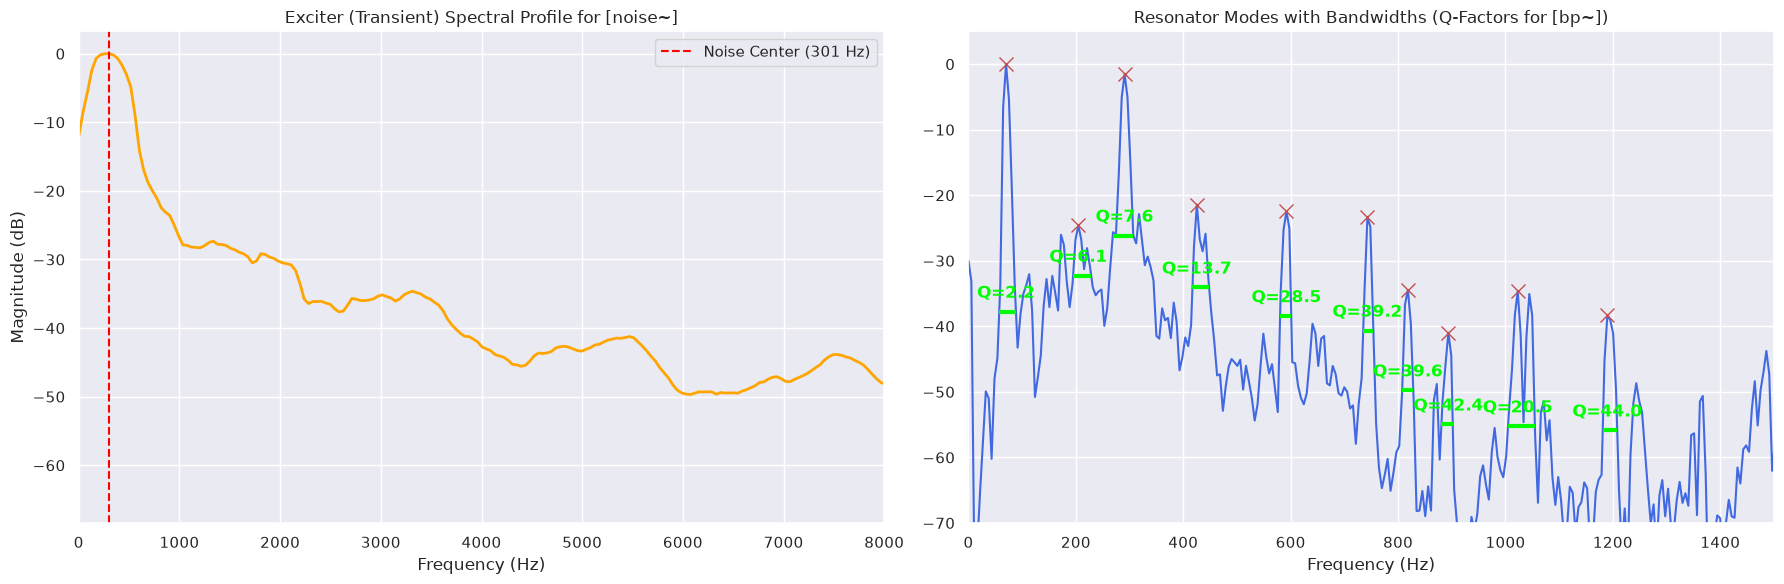

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot 1: The Exciter Envelope
axes[0].plot(freqs_transient, noise_db, color='orange', linewidth=2)
axes[0].axvline(noise_center_freq, color='red', linestyle='--', label=f'Noise Center ({noise_center_freq:.0f} Hz)')
axes[0].set_title("Exciter (Transient) Spectral Profile for [noise~]")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Magnitude (dB)")
axes[0].set_xlim(0, 8000)
axes[0].legend()

# Plot 2: The Resonator Q-Factors
axes[1].plot(freqs, psd_db, color='royalblue')
axes[1].plot(freqs[sorted_peaks], psd_db[sorted_peaks], "rx", markersize=10)

# Draw horizontal lines representing the bandwidth (Q-factor measurement)
for i, peak_idx in enumerate(sorted_peaks):
    left_hz = left_ips[i] * hz_per_bin
    right_hz = right_ips[i] * hz_per_bin
    height = width_heights[i]
    axes[1].hlines(y=height, xmin=left_hz, xmax=right_hz, color='lime', linewidth=3)
    axes[1].annotate(f"Q={pd_patch_data[i]['Q']:.1f}", 
                     (freqs[peak_idx], height), xytext=(0, 10), 
                     textcoords="offset points", ha='center', color='lime', fontweight='bold')

axes[1].set_title("Resonator Modes with Bandwidths (Q-Factors for [bp~])")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_xlim(0, 1500)
axes[1].set_ylim(-70, 5)

plt.tight_layout()
plt.show()